# 02 · Producción regional en el tiempo

Equivale a la sección 4 del paper ancla (arXiv:2503.05658): cómo evoluciona la producción de la
región a lo largo del período.

**Nota de método:** con un volumen tan bajo, la serie anual es ruido. Se agrega por década, como
recomienda el plan.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from astroca.config import get_loader
from astroca.storage import DataStore
from astroca import viz

viz.aplicar_estilo()

loader = get_loader()
store = DataStore(loader.settings().data_dir)

pubs = store.read_latest_raw("publications")
aff = store.read_latest_processed("author_affiliations")

print(f"publicaciones: {len(pubs)}   filas autor-afiliacion: {len(aff)}")
print(f"extraccion:    {store.extraction_date(store.latest_raw_path('publications'))}")

publicaciones: 273   filas autor-afiliacion: 1233
extraccion:    2026-10-23


In [2]:
pubs_anio = pubs.dropna(subset=["year"]).copy()
pubs_anio["year"] = pubs_anio["year"].astype(int)
pubs_anio["decada"] = (pubs_anio["year"] // 10) * 10

print(f"rango: {pubs_anio['year'].min()}–{pubs_anio['year'].max()}")
print(f"primera publicacion: {pubs_anio.loc[pubs_anio['year'].idxmin(), 'title'][:80]}")

rango: 1958–2025
primera publicacion: Anomalous Atmospheric Refraction at Sea


## Publicaciones por década

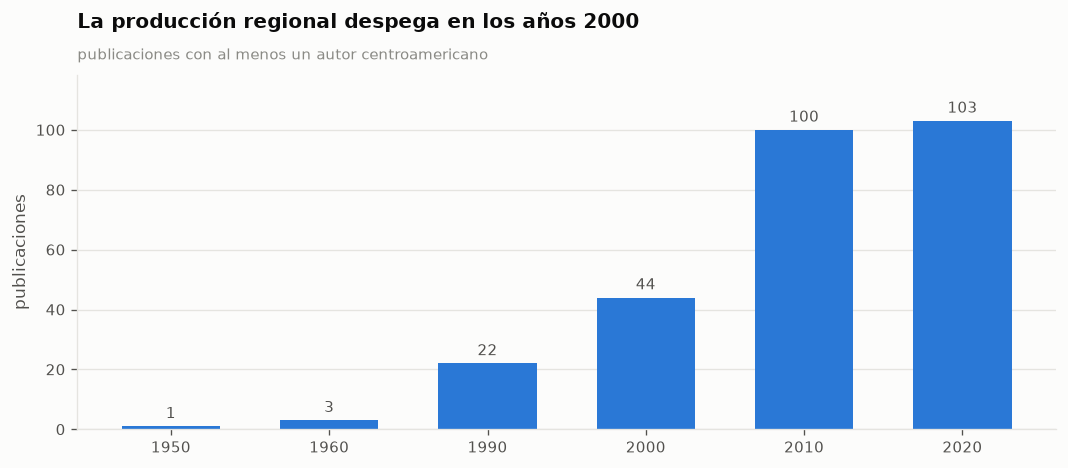

,publicaciones
decada,
1950,1
1960,3
1990,22
2000,44
2010,100
2020,103


In [3]:
por_decada = pubs_anio["decada"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(por_decada.index.astype(str), por_decada.values, color=viz.SERIE_1, width=0.62)
ax.grid(axis="x", visible=False)
viz.limpiar_ejes(ax)

for x, y in zip(range(len(por_decada)), por_decada.values):
    ax.annotate(f"{y}", (x, y), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=9, color=viz.TINTA_SECUNDARIA)

ax.set_ylabel("publicaciones")
ax.set_ylim(0, por_decada.max() * 1.15)
viz.titulo(ax, "La producción regional despega en los años 2000",
           "publicaciones con al menos un autor centroamericano")
plt.tight_layout()
plt.show()

display(por_decada.rename("publicaciones").to_frame())

## Acumulado histórico

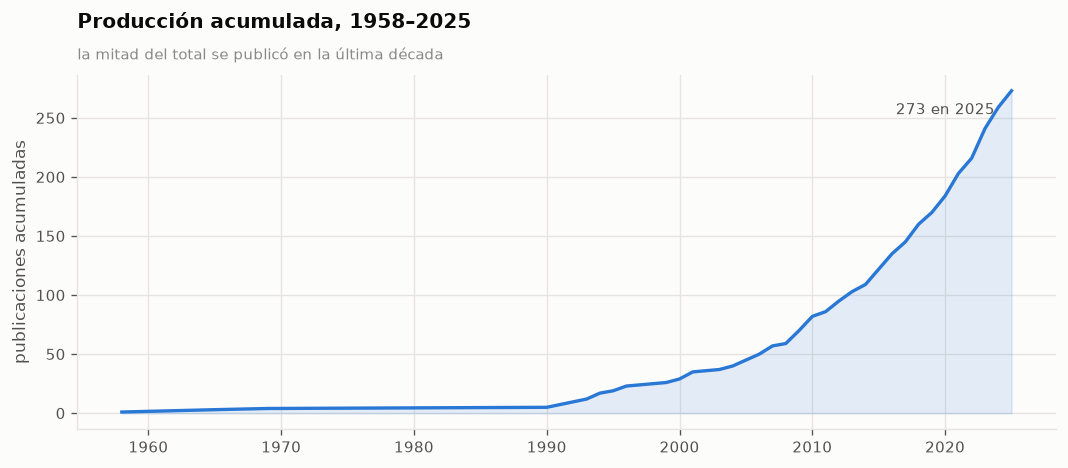

La mitad de toda la produccion historica se alcanzo en 2017.


In [4]:
serie_anual = pubs_anio["year"].value_counts().sort_index()
acumulado = serie_anual.cumsum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(acumulado.index, acumulado.values, color=viz.SERIE_1)
ax.fill_between(acumulado.index, acumulado.values, color=viz.SERIE_1, alpha=0.12)
viz.limpiar_ejes(ax)
ax.set_ylabel("publicaciones acumuladas")

ultimo_anio = int(acumulado.index[-1])
ax.annotate(f"{int(acumulado.iloc[-1])} en {ultimo_anio}",
            (ultimo_anio, acumulado.iloc[-1]), xytext=(-10, -14),
            textcoords="offset points", ha="right", fontsize=9,
            color=viz.TINTA_SECUNDARIA)

viz.titulo(ax, "Producción acumulada, 1958–2025",
           "la mitad del total se publicó en la última década")
plt.tight_layout()
plt.show()

mitad = acumulado[acumulado >= acumulado.iloc[-1] / 2].index[0]
print(f"La mitad de toda la produccion historica se alcanzo en {int(mitad)}.")

## Advertencia sobre el tamaño de la muestra

El plan anticipaba falta de masa crítica. Esta celda la cuantifica: con estos volúmenes, cualquier
métrica normalizada por población o desagregada por año y país va a estar dominada por el ruido.

In [5]:
print(f"publicaciones totales en {pubs_anio['year'].max() - pubs_anio['year'].min()} anios: {len(pubs_anio)}")
print(f"mediana de publicaciones por anio (desde 1990): "
      f"{serie_anual[serie_anual.index >= 1990].median():.0f}")
print(f"anios sin ninguna publicacion: "
      f"{(pubs_anio['year'].max() - pubs_anio['year'].min() + 1) - serie_anual.shape[0]}")

publicaciones totales en 67 anios: 273
mediana de publicaciones por anio (desde 1990): 7
anios sin ninguna publicacion: 32
